# Session 5 demo, part A: comparing groups and testing relationships

This notebook works through the two ideas in Part A.

1. **The two-sample t-test**: do two groups' averages really differ? (independent and paired)
2. **Correlation**: do two numbers move together? (Pearson, and when to reach for Spearman)

It reproduces the numbers on the Part A slides. Everything runs in Colab with nothing to upload.

> **The habit:** before each test, predict the answer. Then compute. The gap between your guess
> and the result is where the learning is.

## 1. Two independent groups: Fund A vs Fund B

Two funds' monthly returns over the past year. Fund A is a growth fund, Fund B a value fund.
Fund A has the higher average, but it also swings harder. Is the gap in averages real, or is it
just Fund A's volatility?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

fund_a = np.array([2.1, -0.5, 3.2, 1.8, 2.5, -1.2, 4.0, 1.1, 2.8, 0.9, 3.5, 1.4])  # growth, %
fund_b = np.array([0.8, 0.5, 1.1, 0.3, 0.9, 0.6, 1.2, 0.4, 0.7, 0.5, 1.0, 0.6])     # value, %

print(f"Fund A: mean {fund_a.mean():.2f}%, sd {fund_a.std(ddof=1):.2f}")
print(f"Fund B: mean {fund_b.mean():.2f}%, sd {fund_b.std(ddof=1):.2f}")
print(f"gap in means: {fund_a.mean() - fund_b.mean():.2f} percentage points")

Fund A: mean 1.80%, sd 1.57
Fund B: mean 0.72%, sd 0.29
gap in means: 1.08 percentage points


**Predict first.** Fund A's mean is about a percentage point higher. But look at its spread. Do you
think a two-sample t-test will call the difference statistically significant at the 5% level?
Write down yes or no before you run the next cell.

In [2]:
# Welch's two-sample t-test: does not assume the two groups have equal variance (safer default).
t_stat, p_value = stats.ttest_ind(fund_a, fund_b, equal_var=False)
print(f"two-sample t = {t_stat:.2f}")
print(f"p-value      = {p_value:.4f}")

alpha = 0.05
if p_value < alpha:
    print(f"\np = {p_value:.4f} < {alpha}: reject H0. The difference in average returns is real.")
else:
    print(f"\np = {p_value:.4f} >= {alpha}: not enough evidence that the averages differ.")

two-sample t = 2.36
p-value      = 0.0368

p = 0.0368 < 0.05: reject H0. The difference in average returns is real.


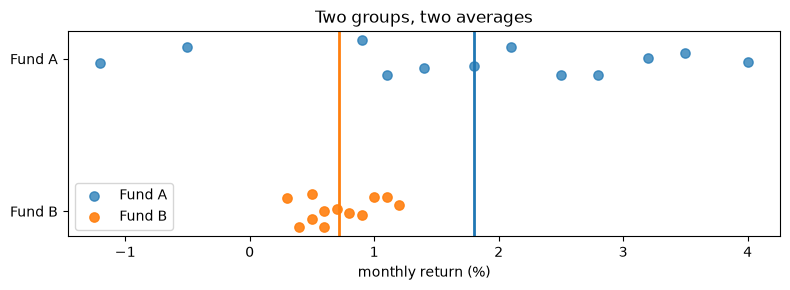

In [3]:
# A picture of the two groups, with their means marked.
fig, ax = plt.subplots(figsize=(8, 3))
rng = np.random.default_rng(5)
ax.scatter(fund_a, 2 + rng.uniform(-0.12, 0.12, len(fund_a)), s=45, alpha=0.75, label="Fund A")
ax.scatter(fund_b, 1 + rng.uniform(-0.12, 0.12, len(fund_b)), s=45, alpha=0.9, label="Fund B")
ax.axvline(fund_a.mean(), color="C0", lw=2); ax.axvline(fund_b.mean(), color="C1", lw=2)
ax.set_yticks([1, 2]); ax.set_yticklabels(["Fund B", "Fund A"])
ax.set_xlabel("monthly return (%)"); ax.set_title("Two groups, two averages")
ax.legend(); plt.tight_layout(); plt.show()

## 2. Two paired measurements: processing time before and after

The same 8 teams had their expense-report processing time measured before and after a new
workflow. This is **paired** data: the same unit measured twice. The right test works on the
differences, not the two columns on their own.

In [4]:
before = np.array([34, 52, 29, 47, 60, 33, 41, 55])  # minutes, 8 teams
after  = np.array([30, 43, 26, 41, 52, 29, 38, 47])
diffs = before - after
print("per-team drop (minutes):", diffs)
print(f"average drop: {diffs.mean():.1f} minutes")

# Paired t-test: works on the per-team differences (same as a one-sample t-test on
# diffs against 0).
t_rel, p_rel = stats.ttest_rel(before, after)
print(f"\npaired t      = {t_rel:.2f}, p = {p_rel:.4f}")

# For contrast, the WRONG test here: treat the two columns as independent groups.
t_ind, p_ind = stats.ttest_ind(before, after, equal_var=False)
print(f"independent t = {t_ind:.2f}, p = {p_ind:.4f}  <- ignores the pairing")

print("\nThe new workflow cut processing time." if p_rel < 0.05 else "No significant change.")

per-team drop (minutes): [4 9 3 6 8 4 3 8]
average drop: 5.6 minutes

paired t      = 6.50, p = 0.0003
independent t = 1.09, p = 0.2969  <- ignores the pairing

The new workflow cut processing time.


**Why pairing matters.** Same 8 numbers, two tests, two answers. Treated as two
independent groups, the big team-to-team spread (29 to 60 minutes) swamps the consistent
~6-minute drop and the test misses it (p about 0.30). Pairing cancels the team-to-team
differences and looks only at each team's own change, which is tight and consistent
(p < 0.001). Independent vs paired is a decision you make from the study design, not
something the software picks for you.

## 3. Is there a relationship? Correlation on Camac

The Session 1 advertising data. Do TV budgets and sales move together? Correlation puts one number
on it, from -1 to +1.

In [5]:
# Loads from a public link, so there is nothing to upload. No internet? It falls back to a local
# copy (data/advertising.csv in the course folder).
DATA_URL = "https://raw.githubusercontent.com/eoinlane/BUU33803-student-notebooks/main/session1/data/advertising.csv"
try:
    ads = pd.read_csv(DATA_URL)
except Exception:
    ads = pd.read_csv("../data/advertising.csv")
print(ads.head())

r = ads["TV"].corr(ads["Sales"])            # Pearson by default
print(f"\nPearson r (TV vs Sales) = {r:.2f}")
print("\nFull correlation matrix:")
print(ads.corr(numeric_only=True).round(2))

      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9

Pearson r (TV vs Sales) = 0.90

Full correlation matrix:
             TV  Radio  Newspaper  Sales
TV         1.00   0.05       0.06   0.90
Radio      0.05   1.00       0.35   0.35
Newspaper  0.06   0.35       1.00   0.16
Sales      0.90   0.35       0.16   1.00


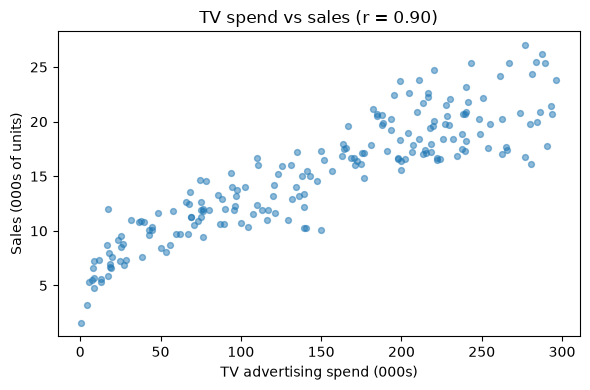

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(ads["TV"], ads["Sales"], s=18, alpha=0.5)
ax.set_xlabel("TV advertising spend (000s)"); ax.set_ylabel("Sales (000s of units)")
ax.set_title(f"TV spend vs sales (r = {ads['TV'].corr(ads['Sales']):.2f})")
plt.tight_layout(); plt.show()

## 4. When Pearson is not the right tool: Spearman

Pearson's r assumes a straight-line link. Spearman's works on ranks, so it handles ordinal data,
monotonic curves, and is less thrown by outliers. On this roughly linear data the two agree
closely; the point is to know they can diverge.

In [7]:
pearson = ads["TV"].corr(ads["Sales"], method="pearson")
spearman = ads["TV"].corr(ads["Sales"], method="spearman")
print(f"Pearson  r = {pearson:.3f}")
print(f"Spearman r = {spearman:.3f}")
print("\nClose here because the link is roughly linear. They would part ways on a curved or "
      "outlier-heavy relationship.")

Pearson  r = 0.901
Spearman r = 0.901

Close here because the link is roughly linear. They would part ways on a curved or outlier-heavy relationship.


## 5. A topical second example: campaign money and votes

Elections run on exactly these tools. Here are 16 hypothetical races: how much each candidate
spent, and the vote share they won. (Non-partisan and illustrative: made-up numbers, generic
candidates, no parties.) Expect a strong positive correlation, which sets up the most important
caveat in this notebook.

Pearson r (spend vs vote share) = 0.77


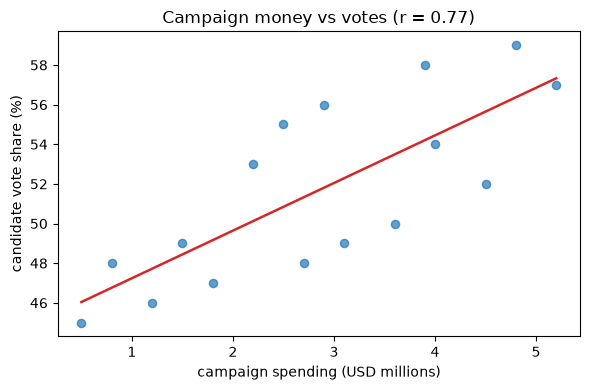

In [8]:
# Campaign spending (USD millions) vs each candidate's vote share (%), across 16 races.
spend  = np.array([1.2, 2.5, 0.8, 3.1, 4.0, 1.8, 2.2, 5.2, 3.6, 0.5, 2.9, 4.5, 1.5, 3.9, 2.7, 4.8])
vshare = np.array([46, 55, 48, 49, 54, 47, 53, 57, 50, 45, 56, 52, 49, 58, 48, 59])

r_camp = np.corrcoef(spend, vshare)[0, 1]
print(f"Pearson r (spend vs vote share) = {r_camp:.2f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(spend, vshare, s=35, alpha=0.7)
m, b = np.polyfit(spend, vshare, 1)
xs = np.array([spend.min(), spend.max()])
ax.plot(xs, m * xs + b, color="C3", lw=1.8)
ax.set_xlabel("campaign spending (USD millions)"); ax.set_ylabel("candidate vote share (%)")
ax.set_title(f"Campaign money vs votes (r = {r_camp:.2f})")
plt.tight_layout(); plt.show()

## The guardrail: correlation is not causation

A strong r says two numbers move together. It does **not** say one causes the other. A third factor
could drive both, the arrow could point either way, or it could be chance. For the campaign money above: does spending win votes, or do strong candidates (who were going to win anyway) attract the money? Probably both. Never write "causes"
from a correlation alone. This is both an exam trap and an audit-judgment point.

---

### Ask Claude

> *I ran a two-sample t-test comparing two funds' monthly returns and got t = 2.36, p = 0.037.
> Explain in plain English what that p-value means for a risk-averse client, and name two things
> the test does not tell me about which fund to choose.*

Paste the result, then push back on anything that overclaims.